# 🤖 8. Modelo base

Se comparan tres modelos para pronosticar la venta del día siguiente de cada negocio:

| Modelo | Pronóstico para el día $t$ | Rol |
|---|---|---|
| **Persistencia** | $\hat y_t = y_{t-1}$ | Línea base trivial: "mañana igual que hoy" |
| **Ingenuo estacional** | $\hat y_t = y_{t-7}$ | Línea base que aprovecha el ciclo semanal (cap. 6) |
| **SVR lineal** | $\log(1+\hat y_t) = w^\top x_t + b$ | Modelo base pedido, dentro del Pipeline del cap. 7 |

Los hiperparámetros del SVR se eligen con la **validación cruzada temporal** del capítulo 6, solo con train. El test (3 – 23 sep) se usa **una sola vez**, al final, con el modelo ya elegido.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, learning_curve
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

from comun import (estilo, cargar_panel, datos_modelo, folds_temporales, crear_pipeline, a_log, rmse_log,
                   RMSE_LOG, CORTE, DIAS, AZUL, NARANJA, VERDE, AMARILLO, GRIS, PALETA, fechas_eje)

estilo()
SEED = 42
panel = cargar_panel()
datos = datos_modelo(panel)
train = datos[datos["fecha"] <= CORTE].sort_values(["fecha", "negocio"]).reset_index(drop=True)
test = datos[datos["fecha"] > CORTE].sort_values(["fecha", "negocio"]).reset_index(drop=True)
folds = folds_temporales(train["fecha"])
print(f"train: {len(train):,} filas ({train['fecha'].min().date()} a {train['fecha'].max().date()}) | "
      f"test: {len(test):,} filas ({test['fecha'].min().date()} a {test['fecha'].max().date()}), {test['negocio'].nunique()} negocios")

train: 22,205 filas (2026-07-15 a 2026-09-02) | test: 9,304 filas (2026-09-03 a 2026-09-23), 445 negocios


In [2]:
# [IA] métricas del cap. 3; se usan para CV, test y bootstrap
def metricas(y, pred, negocio):
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    e, pos = y - pred, y > 0
    z, zp = a_log(y), a_log(pred)
    # R² intra: le quito a cada negocio su media real (solo cuenta la variación día a día)
    media_neg = pd.Series(z).groupby(np.asarray(negocio)).transform("mean").values
    return {
        "RMSE (M COP)": np.sqrt(np.mean(e ** 2)) / 1e6,
        "RMSE log": np.sqrt(np.mean((z - zp) ** 2)),
        "MAPE (%)": np.mean(np.abs(e[pos] / y[pos])) * 100,
        "MdAPE (%)": np.median(np.abs(e[pos] / y[pos])) * 100,
        "WAPE (%)": np.abs(e).sum() / np.abs(y).sum() * 100,
        "R²": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "R² log": 1 - ((z - zp) ** 2).sum() / ((z - z.mean()) ** 2).sum(),
        "R² intra-negocio": 1 - ((z - zp) ** 2).sum() / ((z - media_neg) ** 2).sum(),
    }


def bases(d):
    # los rezagos están en log1p, así que expm1 los devuelve a COP
    return {"Persistencia": np.expm1(d["lag1"]), "Ingenuo estacional": np.expm1(d["lag7"])}

## 🧮 8.1 Validación cruzada temporal: líneas base y búsqueda de hiperparámetros

El SVR tiene dos hiperparámetros:

- $C$: inverso de la regularización. Un $C$ pequeño da coeficientes pequeños (modelo más simple, útil ante la colinealidad del cap. 4).
- $\epsilon$: ancho del "tubo" dentro del cual los errores no se penalizan, en unidades de log. $\epsilon = 0{,}1$ ignora errores menores a ~10 %.

Se prueba una rejilla con los 4 folds temporales (7 días de validación, gap de 7) y se elige la combinación con **menor RMSE log medio**.

In [3]:
rejilla = {"regressor__svr__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0],
           "regressor__svr__epsilon": [0.0, 0.05, 0.1, 0.2, 0.4]}
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)
    busqueda = GridSearchCV(crear_pipeline(), rejilla, cv=folds, scoring=RMSE_LOG, refit=True, return_train_score=True)
    busqueda.fit(train, train["venta_total"])
print("avisos de no convergencia:", sum(issubclass(a.category, ConvergenceWarning) for a in avisos))

cv = pd.DataFrame(busqueda.cv_results_)
cv["C"], cv["epsilon"] = cv["param_regressor__svr__C"].astype(float), cv["param_regressor__svr__epsilon"].astype(float)
cv["RMSE log (val)"], cv["RMSE log (train)"] = -cv["mean_test_score"], -cv["mean_train_score"]
mejor = busqueda.best_params_
print(f"mejor: C = {mejor['regressor__svr__C']}, epsilon = {mejor['regressor__svr__epsilon']}, "
      f"RMSE log CV = {-busqueda.best_score_:.3f} ± {cv.loc[busqueda.best_index_, 'std_test_score']:.3f}")

avisos de no convergencia: 0
mejor: C = 0.1, epsilon = 0.1, RMSE log CV = 0.996 ± 0.084


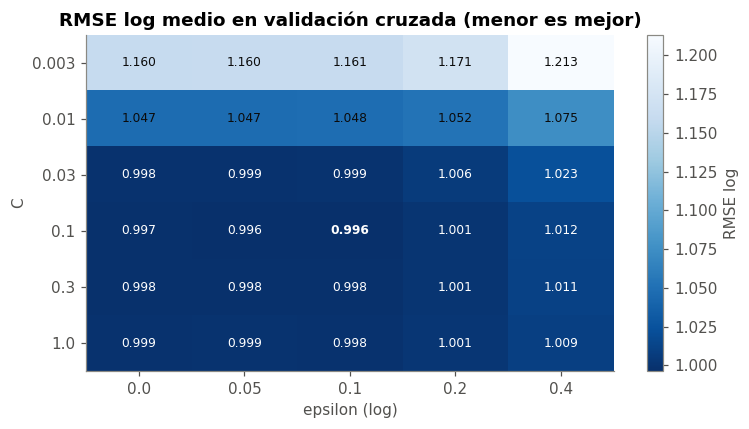

In [4]:
tabla_cv = cv.pivot(index="C", columns="epsilon", values="RMSE log (val)")

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(tabla_cv.values, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(tabla_cv.shape[1])); ax.set_xticklabels(tabla_cv.columns)
ax.set_yticks(range(tabla_cv.shape[0])); ax.set_yticklabels(tabla_cv.index)
ax.grid(False)
for i in range(tabla_cv.shape[0]):
    for j in range(tabla_cv.shape[1]):
        es_mejor = (tabla_cv.index[i] == mejor["regressor__svr__C"]) and (tabla_cv.columns[j] == mejor["regressor__svr__epsilon"])
        ax.text(j, i, f"{tabla_cv.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if es_mejor else "normal", color="#0b0b0b" if tabla_cv.iloc[i, j] > tabla_cv.values.mean() else "white")
ax.set_xlabel("epsilon (log)")
ax.set_ylabel("C")
ax.set_title("RMSE log medio en validación cruzada (menor es mejor)")
fig.colorbar(im, ax=ax, label="RMSE log")
plt.tight_layout()
plt.show()

In [5]:
# [IA] fold por fold: SVR elegido vs. líneas base, en las mismas filas de validación
filas = []
for k, (i_tr, i_val) in enumerate(folds):
    val = train.iloc[i_val]
    fila = {"fold": k + 1, "validación": f"{val['fecha'].min():%d %b} – {val['fecha'].max():%d %b}"}
    for nombre, pred in bases(val).items():
        fila[nombre] = rmse_log(val["venta_total"], pred)
    fila["SVR lineal"] = -cv.loc[busqueda.best_index_, f"split{k}_test_score"]
    filas.append(fila)
por_fold = pd.DataFrame(filas).set_index("fold")
por_fold.loc["media"] = por_fold.mean(numeric_only=True)
por_fold.loc["media", "validación"] = ""
por_fold

,validación,Persistencia,Ingenuo estacional,SVR lineal
fold,,,,
1,06 Aug – 12 Aug,1.27,1.24,1.09
2,13 Aug – 19 Aug,1.16,1.45,1.05
3,20 Aug – 26 Aug,1.03,1.44,0.97
4,27 Aug – 02 Sep,1.03,1.14,0.87
media,,1.12,1.32,1.00


### Interpretación

- La mejor combinación es **$C = 0{,}1$, $\epsilon = 0{,}1$** (RMSE log de CV = 0,996 ± 0,084). La superficie de error es **plana para $C \geq 0{,}03$ y $\epsilon \leq 0{,}1$**: todas esas combinaciones quedan a menos de 0,003 de la mejor, así que la elección no es crítica. Solo empeoran los $C$ muy pequeños, que encogen demasiado los coeficientes, y los $\epsilon$ grandes, que ignoran errores de hasta ~40 %.
- En **los 4 folds** el SVR tiene menor RMSE log que las dos líneas base. La mejora es consistente semana a semana, no la consigue un solo fold.
- En validación cruzada el ingenuo estacional es **peor** que la persistencia (1,32 contra 1,12), sobre todo en los folds 2 y 3. Esos folds contienen días cuyo "mismo día de la semana pasada" fue festivo (7 y 17 ago): el ingenuo copia la caída del festivo a un día normal. El SVR sí sabe que el día a pronosticar no es festivo.
- El error varía entre semanas (el fold 1, con solo 15 días de entrenamiento, es el más difícil). Por eso importa reportar la dispersión y no solo la media.

## 🎯 8.2 Evaluación final en test

El modelo elegido se reentrena con **todo train** (lo hace `GridSearchCV` con `refit=True`) y se evalúa **una sola vez** en test. Para cada día de test las variables usan los datos reales hasta el día anterior, como en el uso real con $h = 1$, pero el modelo **no se reentrena** durante las 3 semanas.

In [6]:
pred_test = {**bases(test), "SVR lineal": busqueda.predict(test)}
res_test = pd.DataFrame({n: metricas(test["venta_total"], p, test["negocio"]) for n, p in pred_test.items()}).T
res_test

,RMSE (M COP),RMSE log,MAPE (%),MdAPE (%),WAPE (%),R²,R² log,R² intra-negocio
Persistencia,7.88,0.92,84.97,14.64,13.83,0.96,0.84,-0.51
Ingenuo estacional,4.74,0.85,133.16,10.61,8.90,0.98,0.86,-0.29
SVR lineal,4.74,0.71,94.03,10.38,8.74,0.98,0.90,0.11


### Interpretación

- Contra la **persistencia**, el SVR es mejor en casi todas las métricas: RMSE log 0,71 contra 0,92, WAPE 8,7 % contra 13,8 %, MdAPE 10,4 % contra 14,6 %. La única excepción es el MAPE (94 % contra 85 %).
- Contra el **ingenuo estacional**, el SVR es claramente mejor en **RMSE log** (0,71 contra 0,85) y en **R² intra-negocio** (0,11 contra −0,29). En las métricas en COP casi empatan: el RMSE es igual (4,74 M) y el WAPE es 8,7 % contra 8,9 %. Para los negocios grandes, que dominan esas métricas, "igual que el mismo día de la semana pasada" ya es un buen pronóstico, y en test no hay festivos que lo confundan.
- El **MAPE** es muy alto en los tres modelos (85–133 %), mientras que la **MdAPE** (su mediana) está entre 10 % y 15 %. El MAPE lo inflan unos pocos días con venta muy pequeña (ver 8.5), como se anticipó en el capítulo 3. Por eso **no sirve para comparar modelos aquí**: ordena distinto que todas las demás métricas.
- El **WAPE** del SVR dice que, sumando todos los negocios, el error total es el 8,7 % de la venta total.

¿Estas diferencias son reales o ruido? Se responde con intervalos de confianza (8.3).

## 📏 8.3 Intervalos de confianza por bootstrap

Las filas de un mismo negocio no son independientes, así que remuestrear filas daría intervalos demasiado estrechos. Se usa un **bootstrap por negocios** (*cluster bootstrap*): en cada réplica se sortean 445 negocios con reemplazo y se toman **todas** sus filas de test. Así el intervalo refleja el tamaño efectivo de muestra (cap. 1). Se hacen 1 000 réplicas con semilla fija y se reportan intervalos percentiles del 95 %.

También se calcula el intervalo de la **diferencia** entre el SVR y cada línea base, en cada réplica. Si no contiene el 0, la mejora es estadísticamente clara.

In [7]:
# [IA] bootstrap por negocio (cluster bootstrap)
B = 1000
rng = np.random.default_rng(SEED)
grupos = test.groupby("negocio").indices
negocios = np.array(list(grupos))
y_te = test["venta_total"].values
claves = ["RMSE log", "WAPE (%)", "MdAPE (%)", "MAPE (%)", "R² log", "R² intra-negocio"]

reps = {n: [] for n in pred_test}
for b in range(B):
    idx = np.concatenate([grupos[n] for n in rng.choice(negocios, len(negocios), replace=True)])
    for n, p in pred_test.items():
        m = metricas(y_te[idx], np.asarray(p)[idx], test["negocio"].values[idx])
        reps[n].append([m[c] for c in claves])
reps = {n: pd.DataFrame(v, columns=claves) for n, v in reps.items()}

ic = pd.concat({n: pd.DataFrame({"estimación": res_test.loc[n, claves],
                                 "IC 2,5 %": r.quantile(0.025), "IC 97,5 %": r.quantile(0.975)})
                for n, r in reps.items()}).round(3)
ic

estimación  IC 2,5 %  IC 97,5 %
Persistencia       RMSE log                0.92      0.68       1.15
                   WAPE (%)               13.83     13.09      14.62
                   MdAPE (%)              14.64     13.83      15.36
                   MAPE (%)               84.97     28.53     191.27
                   R² log                  0.84      0.76       0.90
                   R² intra-negocio       -0.51     -0.81      -0.30
Ingenuo estacional RMSE log                0.85      0.66       1.05
                   WAPE (%)                8.90      8.25       9.65
                   MdAPE (%)              10.61      9.92      11.41
                   MAPE (%)              133.16     24.52     311.61
                   R² log                  0.86      0.80       0.91
                   R² intra-negocio       -0.29     -1.08       0.17
SVR lineal         RMSE log                0.71      0.52       0.86
                   WAPE (%)                8.74      8.18       9.43
                   MdAPE (%)              10.38      9.62      11.09
                   MAPE (%)               94.03     21.20     227.68
                   R² log                  0.90      0.87       0.94
                   R² intra-negocio        0.11     -0.02       0.21

In [8]:
dif = []
for base in ["Persistencia", "Ingenuo estacional"]:
    for c in ["RMSE log", "WAPE (%)", "MdAPE (%)"]:
        d = reps["SVR lineal"][c] - reps[base][c]
        dif.append((base, c, res_test.loc["SVR lineal", c] - res_test.loc[base, c], d.quantile(0.025), d.quantile(0.975),
                    "sí" if d.quantile(0.975) < 0 else ("no (empeora)" if d.quantile(0.025) > 0 else "no concluyente")))
dif = pd.DataFrame(dif, columns=["vs.", "métrica", "SVR − base", "IC 2,5 %", "IC 97,5 %", "¿mejora clara?"]).set_index(["vs.", "métrica"])
dif.round(3)

SVR − base  IC 2,5 %  IC 97,5 %  ¿mejora clara?
vs.                métrica                                                   
Persistencia       RMSE log        -0.21     -0.32      -0.12              sí
                   WAPE (%)        -5.09     -5.63      -4.55              sí
                   MdAPE (%)       -4.27     -4.70      -3.82              sí
Ingenuo estacional RMSE log        -0.15     -0.28      -0.01              sí
                   WAPE (%)        -0.15     -0.59       0.28  no concluyente
                   MdAPE (%)       -0.23     -0.64       0.16  no concluyente

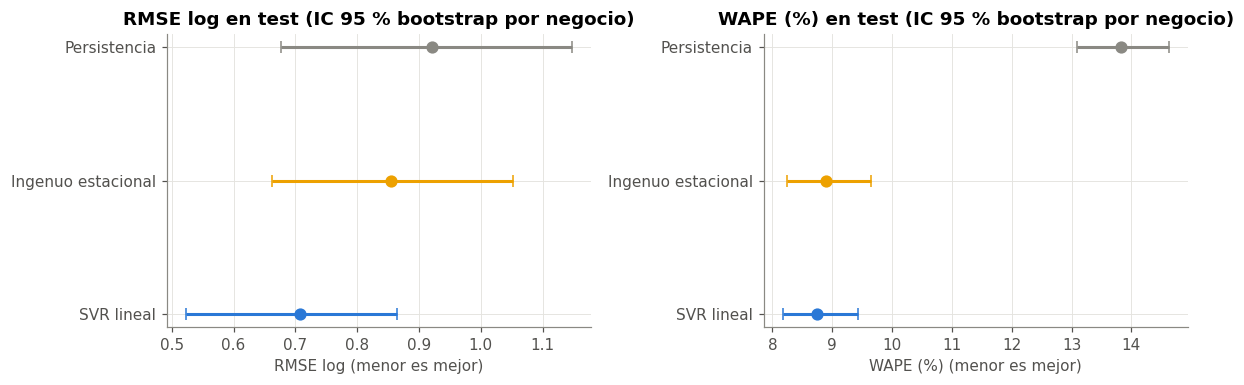

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, c in zip(axes, ["RMSE log", "WAPE (%)"]):
    for k, (n, color) in enumerate(zip(pred_test, [GRIS, AMARILLO, AZUL])):
        est, lo, hi = res_test.loc[n, c], reps[n][c].quantile(0.025), reps[n][c].quantile(0.975)
        ax.errorbar(est, k, xerr=[[est - lo], [hi - est]], fmt="o", color=color, capsize=4, markersize=7, lw=2)
    ax.set_yticks(range(len(pred_test)))
    ax.set_yticklabels(list(pred_test))
    ax.set_title(f"{c} en test (IC 95 % bootstrap por negocio)")
    ax.set_xlabel(c + " (menor es mejor)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretación

- Contra la **persistencia**, el SVR mejora con claridad en RMSE log, WAPE y MdAPE: los tres intervalos de la diferencia quedan enteros por debajo de 0.
- Contra el **ingenuo estacional**, la mejora en **RMSE log** es clara pero su intervalo casi toca el 0 (−0,15; IC −0,28 a −0,01). En **WAPE** y **MdAPE** la diferencia es **no concluyente**: los intervalos contienen el 0. En otras palabras, en septiembre el SVR no es mejor que el ingenuo estacional para los negocios grandes ni para el día típico. Donde sí gana es en los días difíciles (errores grandes en log).
- El **MAPE** tiene intervalos enormes (por ejemplo, 21 % a 228 % para el SVR): depende de qué pocos negocios con días de venta mínima caigan en la muestra. Otra razón para no usarlo como métrica principal.
- El **R² intra-negocio** del SVR (0,11) tiene un intervalo de −0,02 a 0,21: positivo en casi todas las réplicas, pero pequeño.
- Los intervalos son anchos pese a las ~9 300 filas de test porque la unidad independiente es el negocio: **445 negocios**, no 9 300 observaciones.

## 🚩 8.4 ¿Un resultado sospechosamente bueno?

El enunciado advierte que un R² de 80–90 % o más debe hacer sospechar de fuga. Aquí el R² en COP pasa del 0,95 **incluso para las líneas base**, que no tienen ninguna posibilidad de fuga ("mañana igual que la semana pasada").

In [10]:
res_test[["R²", "R² log", "R² intra-negocio"]].round(3)

,R²,R² log,R² intra-negocio
Persistencia,0.95,0.84,-0.51
Ingenuo estacional,0.98,0.86,-0.29
SVR lineal,0.98,0.90,0.11


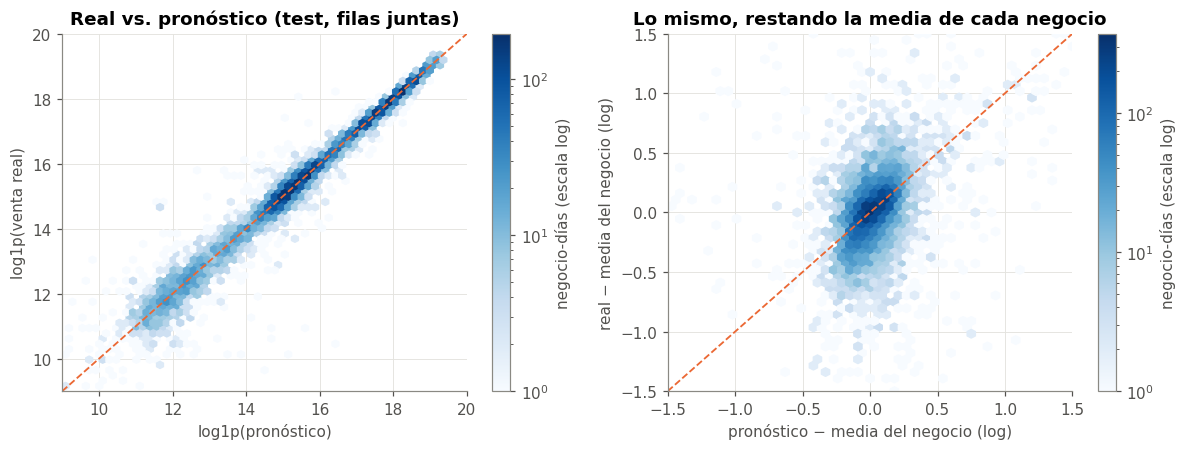

In [11]:
z, zp = a_log(test["venta_total"]), a_log(pred_test["SVR lineal"])
media_neg = z.groupby(test["negocio"]).transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
hb = ax.hexbin(zp, z, gridsize=60, cmap="Blues", mincnt=1, bins="log", extent=(9, 20, 9, 20))
ax.plot([9, 20], [9, 20], color=NARANJA, lw=1.2, ls="--")
ax.set_xlim(9, 20); ax.set_ylim(9, 20)
ax.set_title("Real vs. pronóstico (test, filas juntas)")
ax.set_xlabel("log1p(pronóstico)")
ax.set_ylabel("log1p(venta real)")
fig.colorbar(hb, ax=ax, label="negocio-días (escala log)")

ax = axes[1]
hb = ax.hexbin(zp - media_neg, z - media_neg, gridsize=50, cmap="Blues", mincnt=1, bins="log", extent=(-1.5, 1.5, -1.5, 1.5))
ax.plot([-1.5, 1.5], [-1.5, 1.5], color=NARANJA, lw=1.2, ls="--")
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.set_title("Lo mismo, restando la media de cada negocio")
ax.set_xlabel("pronóstico − media del negocio (log)")
ax.set_ylabel("real − media del negocio (log)")
fig.colorbar(hb, ax=ax, label="negocio-días (escala log)")
plt.tight_layout()
plt.show()

### Interpretación

**No es fuga: es la estructura del panel.** La venta de un negocio grande siempre es mucho mayor que la de un kiosco, así que cualquier modelo que acierte el **tamaño** del negocio explica casi toda la varianza entre filas. Eso infla el R² (panel izquierdo: una diagonal casi perfecta).

Lo difícil es pronosticar la **variación diaria** de cada negocio alrededor de su nivel (panel derecho). Ahí el panorama cambia:

- El **R² intra-negocio** de las líneas base es **negativo** (−0,51 y −0,29): pronostican peor que usar la media de cada negocio.
- El del SVR es **positivo pero modesto** (0,11; IC −0,02 a 0,21): captura una parte de la variación diaria, sobre todo el patrón semanal, pero la mayor parte del ruido diario sigue sin explicar. En el panel derecho la nube es casi redonda.

Esto es coherente con la auditoría del capítulo 5, donde no se encontró fuga. La conclusión honesta es que el **R² alto no es un logro del modelo**: la métrica informativa es el R² intra-negocio y la comparación con las líneas base.

## 🔬 8.5 Diagnóstico de residuos

Residuo = $\log(1 + y) - \log(1 + \hat y)$, en test. Un buen modelo deja residuos sin estructura: sin sesgo, sin autocorrelación y sin patrones por tamaño de negocio.

### a) Autocorrelación de los residuos (ACF)

In [12]:
# [IA] ACF de residuos por negocio (21 días de test) y prueba de Ljung-Box con 7 rezagos
test["resid"] = z - zp
acf_res, p_lb = [], []
for neg, d in test.groupby("negocio"):
    r = d.sort_values("fecha")["resid"].values
    if len(r) < 21 or np.std(r) == 0:
        continue
    acf_res.append(acf(r, nlags=7)[1:])
    p_lb.append(acorr_ljungbox(r, lags=[7])["lb_pvalue"].iloc[0])
acf_res, p_lb = np.array(acf_res), np.array(p_lb)
p_holm = multipletests(p_lb, method="holm")[1]
print(f"negocios con 21 días en test: {len(p_lb)}")
print(f"Ljung-Box (7 rezagos) rechaza 'residuos sin autocorrelación': {np.mean(p_lb < 0.05):.1%} sin corrección, "
      f"{np.mean(p_holm < 0.05):.1%} con Holm")
print(f"sesgo medio del residuo (log): {test['resid'].mean():+.3f}  |  mediana: {test['resid'].median():+.3f}")

negocios con 21 días en test: 438
Ljung-Box (7 rezagos) rechaza 'residuos sin autocorrelación': 17.8% sin corrección, 1.4% con Holm
sesgo medio del residuo (log): -0.049  |  mediana: -0.005


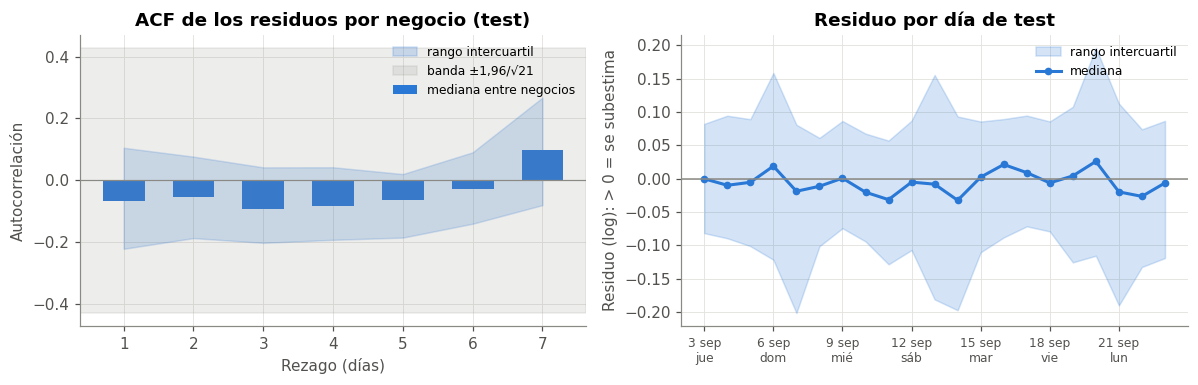

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
lags = np.arange(1, 8)
ax.fill_between(lags, np.percentile(acf_res, 25, axis=0), np.percentile(acf_res, 75, axis=0), color=AZUL, alpha=0.2, label="rango intercuartil")
ax.bar(lags, np.median(acf_res, axis=0), color=AZUL, width=0.6, label="mediana entre negocios")
ax.axhspan(-1.96 / np.sqrt(21), 1.96 / np.sqrt(21), color=GRIS, alpha=0.15, label="banda ±1,96/√21")
ax.axhline(0, color=GRIS, lw=0.8)
ax.set_title("ACF de los residuos por negocio (test)")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
diario = test.groupby("fecha")["resid"].agg(["median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
diario.columns = ["mediana", "p25", "p75"]
ax.fill_between(diario.index, diario["p25"], diario["p75"], color=AZUL, alpha=0.2, label="rango intercuartil")
ax.plot(diario.index, diario["mediana"], color=AZUL, lw=2, marker="o", markersize=4, label="mediana")
ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(diario.index[::3])
ax.set_xticklabels([f"{f.day} sep\n{DIAS[f.dayofweek]}" for f in diario.index[::3]], fontsize=8)
ax.set_title("Residuo por día de test")
ax.set_ylabel("Residuo (log): > 0 = se subestima")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### Interpretación

- La mediana de la ACF de los residuos es pequeña en todos los rezagos y queda dentro de la banda. El leve sesgo negativo es esperable en series de solo 21 puntos: la ACF muestral tiende a $-1/n$. Ljung-Box rechaza "sin autocorrelación" en el 18 % de los negocios sin corregir, y solo en el **1,4 % con Holm**. **No queda autocorrelación importante** sin modelar: los rezagos 1, 7 y 14 capturan la dependencia temporal.
- El residuo diario oscila alrededor de 0 (mediana −0,005 en log) sin tendencia durante las 3 semanas de test. El modelo **no se degrada** a medida que se aleja del final de train, lo que es consistente con que no hubo deriva global (cap. 6.4). La media del residuo (−0,05) es más negativa que la mediana porque en los días sin venta el modelo pronostica de más.

### b) Error por tamaño de negocio y efecto de los días sin venta

In [14]:
# terciles de tamaño según el nivel histórico (calculado con datos anteriores a cada día)
cortes = train.groupby("negocio")["nivel"].last().quantile([1 / 3, 2 / 3]).values
test["tamaño"] = pd.cut(test["nivel"], [-np.inf, *cortes, np.inf], labels=["pequeños", "medianos", "grandes"])
por_tam = pd.DataFrame({t: metricas(d["venta_total"], pred_test["SVR lineal"][d.index], d["negocio"])
                        for t, d in test.groupby("tamaño", observed=True)}).T
por_tam["negocios"] = test.groupby("tamaño", observed=True)["negocio"].nunique()
por_tam["venta mediana (M COP)"] = test.groupby("tamaño", observed=True)["venta_total"].median() / 1e6
por_tam[["negocios", "venta mediana (M COP)", "RMSE log", "MAPE (%)", "MdAPE (%)", "WAPE (%)", "R² intra-negocio"]].round(2)

,negocios,venta mediana (M COP),RMSE log,MAPE (%),MdAPE (%),WAPE (%),R² intra-negocio
pequeños,154,0.68,1.12,39.21,20.45,23.89,0.12
medianos,153,5.31,0.46,237.28,10.42,14.58,0.02
grandes,150,51.76,0.15,9.40,6.18,7.87,0.24


In [15]:
sin_ceros = test["sin_registro"] == 0
print(f"días sin venta en test: {(~sin_ceros).sum()} de {len(test):,} ({(~sin_ceros).mean():.2%})")
print(f"RMSE log con todos los días: {rmse_log(test['venta_total'], pred_test['SVR lineal']):.3f}")
print(f"RMSE log sin los días sin venta: {rmse_log(test.loc[sin_ceros, 'venta_total'], pred_test['SVR lineal'][sin_ceros]):.3f}")
peso = (test.loc[~sin_ceros, "resid"] ** 2).sum() / (test["resid"] ** 2).sum()
print(f"parte del error cuadrático (log) que viene de los días sin venta: {peso:.0%}")

días sin venta en test: 37 de 9,304 (0.40%)
RMSE log con todos los días: 0.707
RMSE log sin los días sin venta: 0.382
parte del error cuadrático (log) que viene de los días sin venta: 71%


### Interpretación

- El error **relativo típico** crece a medida que el negocio es más pequeño: la MdAPE es 6 % en los grandes, 10 % en los medianos y 20 % en los pequeños (WAPE: 8 %, 15 % y 24 %). Un kiosco tiene días mucho más irregulares que una EDS.
- El **MAPE** no sigue ese orden: es 237 % en los medianos, contra 39 % en los pequeños. Lo dispara un puñado de días con venta casi nula en negocios medianos, donde un pronóstico normal da errores de miles por ciento. Es la prueba de que el MAPE aquí mide los días raros, no el desempeño típico.
- Los **días sin venta** son solo 37 de 9 304 (0,4 %), pero generan el **71 % del error cuadrático en log**. El modelo nunca pronostica 0, y $\log(1)$ frente a $\log(10^7)$ es una distancia de ~16. Sin esos días el RMSE log baja de 0,71 a 0,38.

**Mejoras que se desprenden** (fuera del alcance del modelo base): un modelo en dos partes (probabilidad de vender × monto si vende) para los días sin venta, y modelos o ponderaciones por tipo de negocio.

## 📚 8.6 Curva de aprendizaje

¿El modelo mejoraría con más datos? Se entrena con fracciones crecientes de las filas de entrenamiento de cada fold (tomadas al azar con semilla fija) y se mide el error en el fold de validación correspondiente.

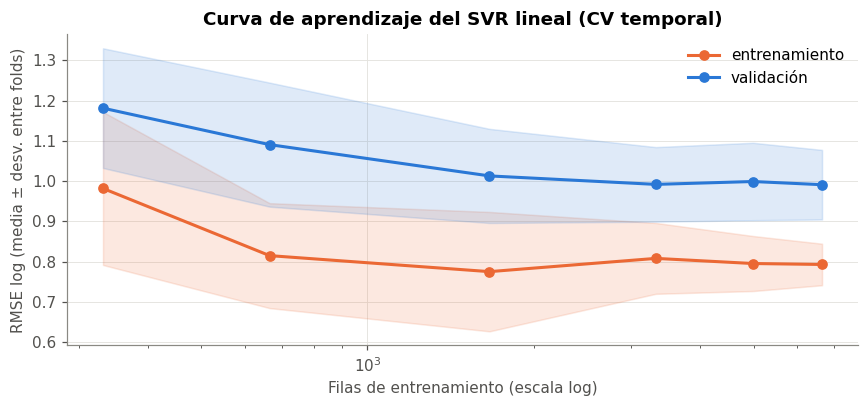

,filas (media entre folds),RMSE log train,RMSE log validación
0,332,0.98,1.18
1,665,0.81,1.09
2,1663,0.78,1.01
3,3327,0.81,0.99
4,4990,0.80,1.00
5,6654,0.79,0.99


In [16]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    tamanos, err_tr, err_val = learning_curve(
        crear_pipeline(C=mejor["regressor__svr__C"], epsilon=mejor["regressor__svr__epsilon"]),
        train, train["venta_total"], cv=folds, scoring=RMSE_LOG,
        train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0], shuffle=True, random_state=SEED)
err_tr, err_val = -err_tr, -err_val

fig, ax = plt.subplots(figsize=(8, 3.8))
for err, color, nombre in [(err_tr, NARANJA, "entrenamiento"), (err_val, AZUL, "validación")]:
    ax.plot(tamanos, err.mean(axis=1), color=color, marker="o", lw=2, label=nombre)
    ax.fill_between(tamanos, err.mean(axis=1) - err.std(axis=1), err.mean(axis=1) + err.std(axis=1), color=color, alpha=0.15)
ax.set_xscale("log")
ax.set_title("Curva de aprendizaje del SVR lineal (CV temporal)")
ax.set_xlabel("Filas de entrenamiento (escala log)")
ax.set_ylabel("RMSE log (media ± desv. entre folds)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
pd.DataFrame({"filas (media entre folds)": tamanos, "RMSE log train": err_tr.mean(axis=1), "RMSE log validación": err_val.mean(axis=1)}).round(3)

### Interpretación

- La curva de validación baja de 1,18 a ~1,00 y se **aplana desde unas 1 600 filas**: más filas del mismo tipo ya no ayudan. La de entrenamiento se estabiliza en ~0,80.
- Queda una **brecha estable de ~0,2** entre ambas. No es sobreajuste de manual (el error de train no se acerca a 0 ni la brecha crece al quitar datos). Lo más probable es que refleje que validar es pronosticar **otra semana**, con choques que no estaban en train, y que el gap de 7 días hace la validación más exigente.
- Con ambas curvas planas, el error que queda es **sesgo** (un modelo lineal global es demasiado simple para la variación diaria de cada negocio) más ruido irreducible, no falta de filas.
- Por eso, para mejorar hay que **cambiar el modelo o las variables** (no linealidades, interacciones negocio × día, modelo para los ceros), no solo juntar más filas. Lo que sí ayudaría es **más historia**: más semanas para estimar patrones de cada negocio, festivos y estacionalidad mensual.

## 🧾 8.7 Interpretación de los coeficientes

Como las variables están estandarizadas, cada coeficiente es el cambio en $\log(1 + \text{venta})$ cuando la variable sube **una desviación estándar**, con las demás fijas. En porcentaje: $e^{w} - 1$. Para el día de la semana, el coeficiente es la diferencia frente al **lunes** (la categoría de referencia).

```{warning}
Por la colinealidad entre las variables de nivel (VIF alto, cap. 4.3), los coeficientes **individuales** de ese grupo son inestables: el modelo puede repartir el "nivel" entre `lag1`, `lag7`, `media7` y `nivel` de muchas formas casi equivalentes. Se interpretan **por grupo**.
```

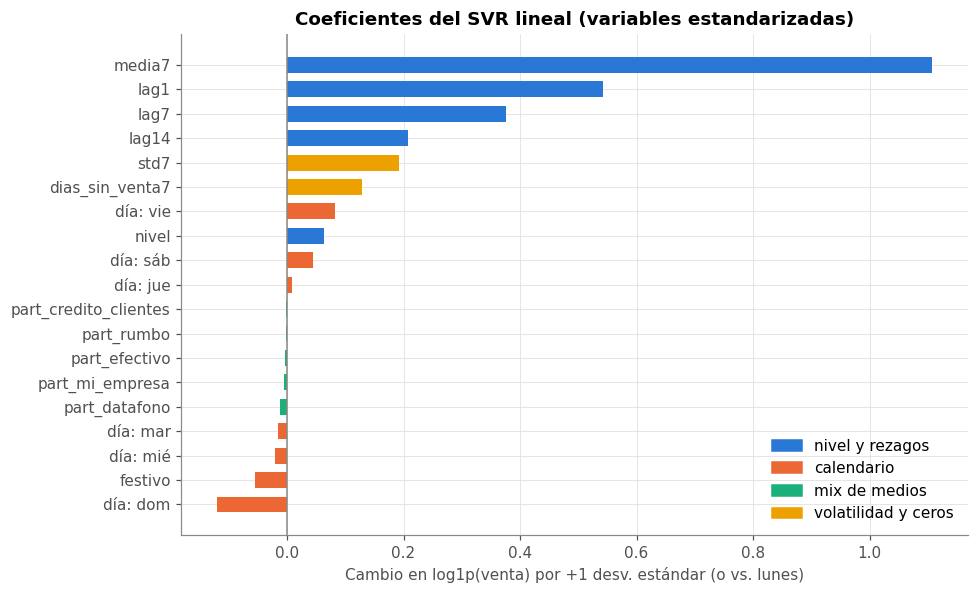

intercepto (log): 15.50  →  5.4 M COP para un negocio 'promedio' un lunes


In [17]:
svr = busqueda.best_estimator_.regressor_.named_steps["svr"]
nombres = busqueda.best_estimator_.regressor_.named_steps["pre"].get_feature_names_out()
coef = pd.Series(svr.coef_, index=[n.split("__")[1] for n in nombres])
coef.index = [f"día: {DIAS[int(n.split('_')[-1])]}" if n.startswith("dia_semana") else n for n in coef.index]

grupo = {"lag1": "nivel y rezagos", "lag7": "nivel y rezagos", "lag14": "nivel y rezagos", "media7": "nivel y rezagos",
         "nivel": "nivel y rezagos", "std7": "volatilidad y ceros", "dias_sin_venta7": "volatilidad y ceros",
         "festivo": "calendario"}
grupos = pd.Series({n: grupo.get(n, "mix de medios" if n.startswith("part_") else "calendario") for n in coef.index})
colores = {"nivel y rezagos": AZUL, "calendario": NARANJA, "mix de medios": VERDE, "volatilidad y ceros": AMARILLO}

orden = coef.sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(orden, coef[orden], color=[colores[grupos[n]] for n in orden], height=0.65)
ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Coeficientes del SVR lineal (variables estandarizadas)")
ax.set_xlabel("Cambio en log1p(venta) por +1 desv. estándar (o vs. lunes)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in colores.items()], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()
print(f"intercepto (log): {svr.intercept_[0]:.2f}  →  {np.expm1(svr.intercept_[0]) / 1e6:,.1f} M COP para un negocio 'promedio' un lunes")

In [18]:
efecto = pd.DataFrame({"grupo": grupos, "coeficiente": coef, "efecto (%)": np.expm1(coef) * 100})
suma_grupo = efecto.groupby("grupo")["coeficiente"].agg(lambda s: s.abs().sum()).sort_values(ascending=False).rename("suma de |coef.|")
print(suma_grupo.round(3).to_string())
efecto.sort_values("coeficiente", key=np.abs, ascending=False).round(3)

grupo
nivel y rezagos       2.30
calendario            0.35
volatilidad y ceros   0.32
mix de medios         0.02


,grupo,coeficiente,efecto (%)
media7,nivel y rezagos,1.11,202.69
lag1,nivel y rezagos,0.54,71.94
lag7,nivel y rezagos,0.38,45.53
lag14,nivel y rezagos,0.21,23.10
std7,volatilidad y ceros,0.19,21.13
dias_sin_venta7,volatilidad y ceros,0.13,13.76
día: dom,calendario,-0.12,-11.30
día: vie,calendario,0.08,8.61
nivel,nivel y rezagos,0.06,6.53
festivo,calendario,-0.06,-5.41


### Interpretación

- **Nivel y rezagos** es, por mucho, el grupo con más peso (suma de |coef.| = 2,30): el mejor predictor de la venta de mañana es cuánto vende normalmente el negocio y cuánto vendió recientemente. El modelo reparte el peso entre `media7` (1,11), `lag1` (0,54), `lag7` (0,38) y `lag14` (0,21), en línea con la ACF (cap. 6.2). El `nivel` histórico casi no pesa (0,06): una vez conocida la última semana, la media desde julio aporta poco. El reparto exacto es inestable por la colinealidad.
- **Calendario** (0,35): frente al lunes, el **domingo** baja la venta un 11 % y el **viernes** la sube un 9 % (sábado +4 %). El orden coincide con el patrón semanal de los capítulos 4 y 6. El coeficiente de `festivo` es negativo (−5 %), pero mucho menor que las caídas de 15–23 % medidas en 6.5: con solo 3 festivos, la regularización lo encoge.
- **Volatilidad y ceros** (0,32): `std7` y `dias_sin_venta7` tienen coeficientes **positivos**. Parece raro, pero tiene sentido: una semana con días anómalos (cero o muy bajos) hunde la media en log, y estas variables le permiten al modelo "devolver" el nivel normal del negocio.
- **Mix de medios** (0,02): coeficientes casi nulos. Como se vio en 4.2 c, el mix distingue negocios entre sí, pero una vez que el modelo conoce el nivel del negocio no aporta nada al día a día. Candidatas a eliminarse en una versión más simple.

## ✅ 8.8 Conclusiones del modelo base

In [19]:
final = res_test.loc[:, ["RMSE (M COP)", "RMSE log", "MAPE (%)", "MdAPE (%)", "WAPE (%)", "R²", "R² intra-negocio"]].copy()
final["RMSE log CV (media)"] = [por_fold.loc["media", n] for n in final.index]
final.round(3)

,RMSE (M COP),RMSE log,MAPE (%),MdAPE (%),WAPE (%),R²,R² intra-negocio,RMSE log CV (media)
Persistencia,7.88,0.92,84.97,14.64,13.83,0.95,-0.51,1.12
Ingenuo estacional,4.74,0.85,133.16,10.61,8.90,0.98,-0.29,1.32
SVR lineal,4.74,0.71,94.03,10.38,8.74,0.98,0.11,1.00


| Pregunta | Respuesta |
|---|---|
| ¿El SVR lineal le gana a las líneas base? | **A la persistencia, sí** (RMSE log, WAPE y MdAPE, con intervalos bootstrap por negocio que no tocan el 0). **Al ingenuo estacional, solo en RMSE log e intra-negocio**. En WAPE y MdAPE la diferencia no es concluyente |
| ¿Hay fuga de datos? | **No se encontró** (cap. 5). El R² alto lo explica la heterogeneidad entre negocios: también lo tienen las líneas base |
| ¿Qué tan bueno es para el día a día? | **Modesto.** R² intra-negocio 0,11. MdAPE 10,4 %, WAPE 8,7 %. Error típico de 6 % en negocios grandes y 20 % en pequeños |
| ¿Sobreajusta? | **No.** Las curvas de aprendizaje de train y validación quedan juntas |
| ¿Qué limita el error? | Los días sin venta (0,4 % de los días, 71 % del error cuadrático en log), el sesgo de un modelo lineal global y la irregularidad de los negocios pequeños |
| ¿Sirve el MAPE? | **Poco.** Lo dominan días de venta casi nula, tiene intervalos enormes y ordena los modelos distinto que todas las demás métricas. Se reporta porque lo pide el enunciado, pero las conclusiones se basan en RMSE log, WAPE y MdAPE |

```{note}
**Próximos pasos sugeridos.** (1) Un modelo en dos partes para los días sin venta. (2) Modelos no lineales (por ejemplo *gradient boosting*) que capten interacciones como negocio × día de la semana. (3) Corregir el sesgo de retransformación al volver de log a COP (por ejemplo, el *smearing* de Duan). (4) Más historia para modelar festivos y estacionalidad mensual. (5) Un tratamiento de arranque en frío para los negocios nuevos.
```

```{warning}
**Límites de validez.** El test cubre 3 semanas de septiembre de 2026 sin festivos, y 445 negocios de una sola operadora. Los resultados no se deben extrapolar a temporadas altas, a festivos ni a negocios nuevos sin historia.
```